## Step 1: connect and setup
- Connect to the MySQL database and set one chart style for the whole notebook. All numbers come from SQL queries, so the EDA uses the database instead of CSV files.

In [1]:
import os                                            # read environment variables
import pandas as pd                                  # tables
import matplotlib.pyplot as plt                      # charts
from dotenv import load_dotenv                       # reads the .env file with the secrets
from sqlalchemy import create_engine, text          # connection + raw SQL

load_dotenv("../.env", override=True)                # .env sits one level above notebook/
engine = create_engine(os.getenv("CON_STRING"))      # connection to behind_the_label

def q(sql):
    """Run a SQL text and return the result as a table."""
    return pd.read_sql(text(sql), engine)

# one colour rule for the whole project: accent = EU-banned, grey = everything else
ACCENT, GREY, INK = "#C2410C", "#9AA5B1", "#1F2933"
SRC = "Source: California Safe Cosmetics Program (CDPH), EU CosIng Annexes II-VI"

def style(ax, title, source=SRC):
    """Same clean look for every chart: finding as title, quiet grid, no top/right frame."""
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=12)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#CBD2D9")
    ax.tick_params(colors="#52606D")
    ax.set_axisbelow(True)
    ax.figure.text(0.01, -0.02, source, fontsize=8, color="#7B8794")

print(q("SELECT COUNT(*) AS reports FROM reports"))   # quick test: should be 114,381

   reports
0   114381


## Step 2: chapter 1, the most frequent chemicals
- Which chemicals are reported in the most products? I count DISTINCT products, because a product can contain a chemical in several shades. Titanium dioxide is expected to dominate, so I show it openly.

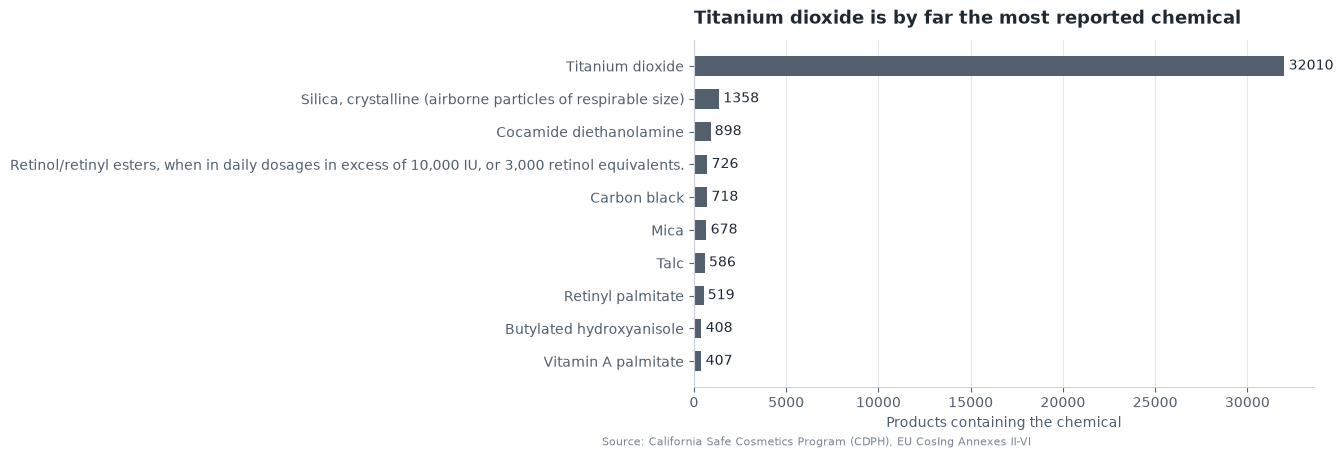

In [2]:
# 1. Top 10 chemicals by number of products (TiO2 included on purpose)
top = q("""SELECT ch.chemical_name, COUNT(DISTINCT r.cdph_id) AS products
           FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
           GROUP BY ch.chemical_name ORDER BY products DESC LIMIT 10""")

# 2. Horizontal bars, largest on top; grey because this chart is not about EU status
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(top["chemical_name"][::-1], top["products"][::-1], height=0.6, color="#52606D")
ax.bar_label(bars, padding=3, color=INK, fmt="%d")   # number at the bar end
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products containing the chemical", color="#52606D")
style(ax, "Titanium dioxide is by far the most reported chemical")
fig.savefig("../images/01_top_chemicals.png", dpi=200, bbox_inches="tight")
plt.show()

**Chart 1: top 10 chemicals, including TiO2**
- **What it shows:** Titanium dioxide appears in 32,010 of 36,972 products (about 87%), far ahead of every other chemical.
- **Chemist's note:** TiO2 is the standard white pigment and UV filter. California lists it only in its airborne, unbound, respirable particle form, which matters for powders and sprays that can be inhaled. A report therefore does not mean that every product is hazardous.

**Findings:** 

- Titanium dioxide appears in 32,010 of 36,972 products (about 87%); the next chemicals, crystalline silica (1,358) and cocamide diethanolamine (898), are far behind. TiO2 is reportable in its airborne, respirable form, so it dominates mostly colour and powder products. For comparisons between chemicals it is analysed separately.

## Step 3: chapter 1, reporting over time
- How did reporting develop over time? Left: how many products were reported for the first time in each year. Right: how many report entries had the chemical removed in each year. The removal date is a sign of reformulation.

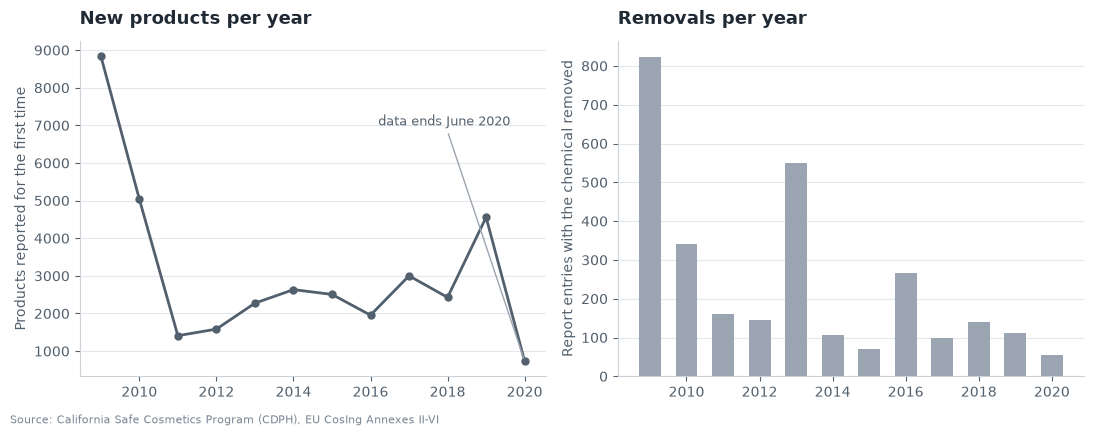

In [3]:
# 1. New products per year: take the earliest report date of each product
new_per_year = q("""
    SELECT YEAR(first_date) AS year, COUNT(*) AS new_products
    FROM (SELECT cdph_id, MIN(initial_date_reported) AS first_date      -- first report of each product
          FROM reports GROUP BY cdph_id) t
    WHERE first_date IS NOT NULL
    GROUP BY year ORDER BY year""")

# 2. Removals per year: report entries where the chemical was taken out of the product
removed_per_year = q("""
    SELECT YEAR(chemical_date_removed) AS year, COUNT(*) AS removed_entries
    FROM reports
    WHERE chemical_date_removed IS NOT NULL
    GROUP BY year ORDER BY year""")

# 3. Two small charts side by side (different measures, so no shared axis)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.plot(new_per_year["year"], new_per_year["new_products"], color="#52606D", linewidth=2, marker="o", markersize=5)
ax1.yaxis.grid(True, color="#E4E7EB")
ax1.set_ylabel("Products reported for the first time", color="#52606D")
ax1.annotate("data ends June 2020", xy=(2020, 735), xytext=(2016.2, 7000), color="#52606D", fontsize=9,
             arrowprops=dict(arrowstyle="-", color="#9AA5B1"))     # note pointing at the last point
style(ax1, "New products per year", source="")

ax2.bar(removed_per_year["year"], removed_per_year["removed_entries"], width=0.6, color=GREY)
ax2.yaxis.grid(True, color="#E4E7EB")
ax2.set_ylabel("Report entries with the chemical removed", color="#52606D")
style(ax2, "Removals per year", source=SRC)

fig.tight_layout()                                           # avoid overlapping labels
fig.savefig("../images/02_reporting_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

**Chart 2: reporting over time**
- **What it shows:** Most products were reported in the first wave of 2009-2010; from 2011 on, 1,400-4,600 new products per year.
- **Note:** 2009-2010 is the start of the program (existing products were reported for the first time), not a real peak. 2020 is incomplete, because the data ends in June 2020.

**Findings**
  
- 2009-2010 is the initial reporting wave (13,887 products), not growth. From 2011 on, 1,400-4,600 new products per year; 2019 shows a second bump; 2020 is incomplete (data ends June 2020). Removals peak in 2009 (824) with a second peak in 2013 (551); both are described, not explained.

## Step 4: chapter 2, the two rulebooks

- Chapter 2 compares California with the EU. Chart 3: which banned chemicals appear in the most products. Chart 4: how often chemicals were removed, by EU status (without TiO2). Chart 5: which product categories are most affected. The accent colour always means “banned in the EU”.

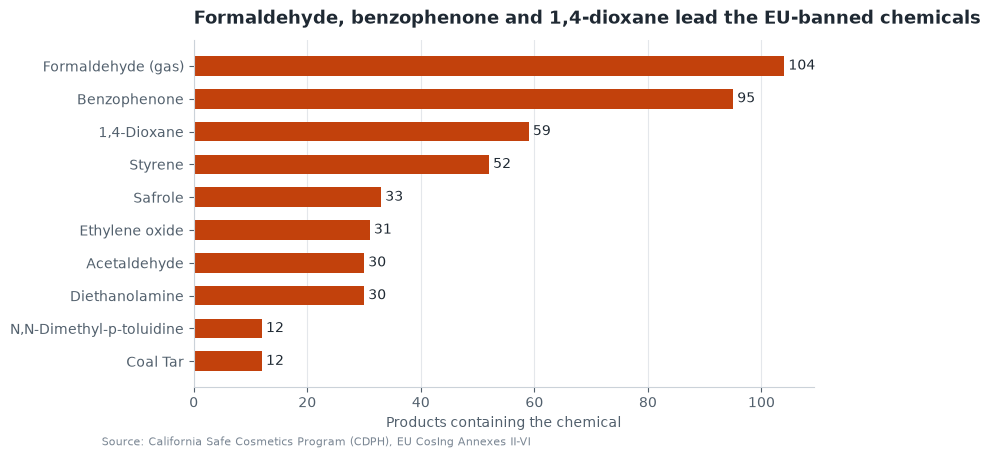

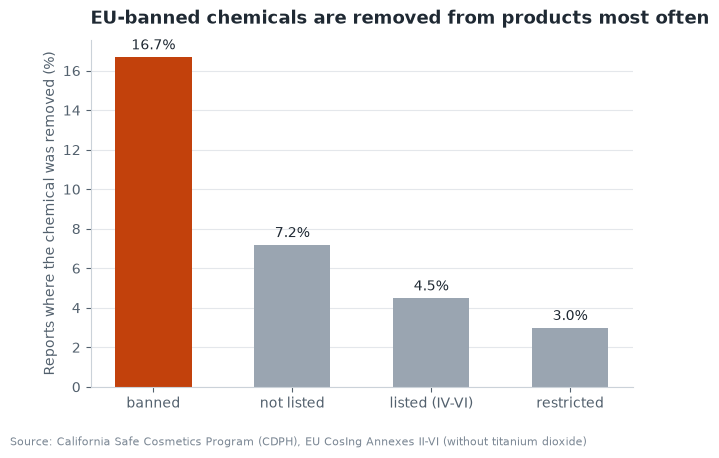

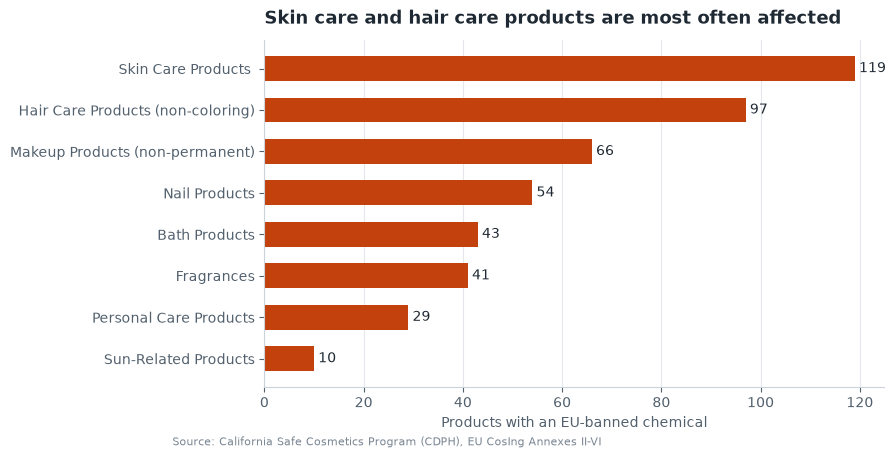

In [4]:
# --- Chart 3: banned chemicals found in the most products ---
chem = q("""SELECT ch.chemical_name, COUNT(DISTINCT r.cdph_id) AS products
            FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
            WHERE r.eu_banned = 1 GROUP BY ch.chemical_name ORDER BY products DESC LIMIT 10""")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(chem["chemical_name"][::-1], chem["products"][::-1], height=0.6, color=ACCENT)
ax.bar_label(bars, padding=3, color=INK, fmt="%d")
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products containing the chemical", color="#52606D")
style(ax, "Formaldehyde, benzophenone and 1,4-dioxane lead the EU-banned chemicals")
fig.savefig("../images/03_banned_chemicals.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Chart 4: removal rate by EU status (without titanium dioxide) ---
rem = q("""SELECT eu_status_of(r.cas_number) AS eu_status, ROUND(100 * AVG(r.is_removed), 1) AS removed_percent
           FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
           WHERE ch.is_tio2 = 0 GROUP BY eu_status""")
order = ["banned", "not listed", "listed (IV-VI)", "restricted"]          # fixed order: strictest first
rem = rem.set_index("eu_status").loc[order].reset_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = [ACCENT if s == "banned" else GREY for s in rem["eu_status"]]   # accent only for banned
bars = ax.bar(rem["eu_status"], rem["removed_percent"], width=0.55, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3, color=INK)
ax.yaxis.grid(True, color="#E4E7EB")
ax.set_ylabel("Reports where the chemical was removed (%)", color="#52606D")
style(ax, "EU-banned chemicals are removed from products most often", SRC + " (without titanium dioxide)")
fig.savefig("../images/04_removal_by_eu_status.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Chart 5: product categories with banned chemicals ---
cat = q("""SELECT pc.primary_category, COUNT(DISTINCT b.cdph_id) AS products
           FROM (SELECT DISTINCT cdph_id FROM reports WHERE eu_banned = 1) b
           JOIN product_categories pc ON pc.cdph_id = b.cdph_id
           GROUP BY pc.primary_category ORDER BY products DESC LIMIT 8""")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(cat["primary_category"][::-1], cat["products"][::-1], height=0.6, color=ACCENT)
ax.bar_label(bars, padding=3, color=INK, fmt="%d")
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products with an EU-banned chemical", color="#52606D")
style(ax, "Skin care and hair care products are most often affected")
fig.savefig("../images/05_banned_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

**Chart 3: banned chemicals found in the most products**
- **What it shows:** Formaldehyde (104 products), benzophenone (95) and 1,4-dioxane (59) are the EU-banned chemicals found in the most products.
 - **Chemist's note:** Several of these are not added on purpose. 1,4-Dioxane is a by-product of ethoxylation (used to make mild surfactants), and ethylene oxide and styrene are residues of production. "Banned" in the EU means banned as an ingredient; traces that are technically unavoidable are tolerated. Benzophenone (CAS 119-61-9) is not the same substance as benzophenone-3 (oxybenzone), the UV filter.
   
**Chart 4: removal rate by EU status**
- **What it shows:** EU-banned chemicals were removed in 16.7% of the reports, other groups in 3.0-7.2% (without TiO2).
- **Chemist's note:** Chemicals on a positive list or with a restriction may legally stay in the product, so there is less reason to remove them. Only where the EU forbids a substance does the formulation have to change. This is an association, not proof of cause; the statistical test follows (H1).

**Chart 5: banned chemicals by product category**
- **What it shows:** Skin care ([119]) and hair care ([97]) products are most often affected, followed by makeup ([66]) and nail products ([54]).
- **Chemist's note:** The counts depend on the size of each category. Plausible sources are by-products in ethoxylated ingredients and preservatives that release formaldehyde; the data do not show the source, so I describe it as a likely reason only.

## Step 5: the four planned charts

 - The four planned charts. Chapter 1 describes the California data: the most frequent chemicals without TiO2, the product categories, and the companies, with Procter & Gamble marked. Chapter 2 shows how much of what is reported is banned or restricted in the EU.

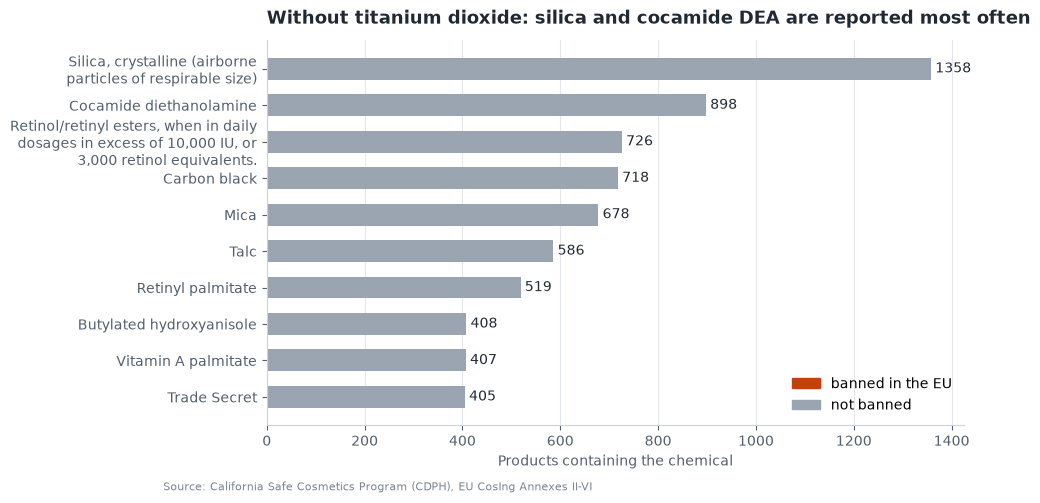

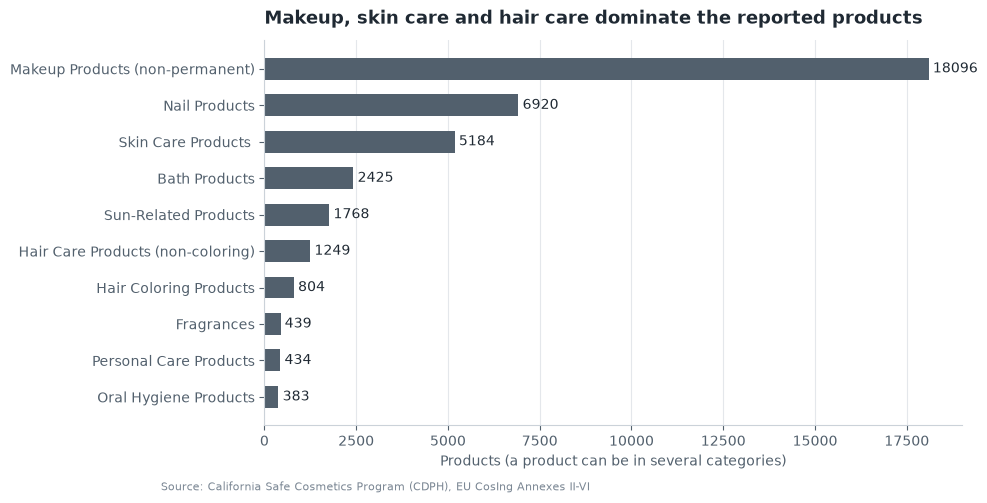

                     company_name  products
531  The Procter & Gamble Company       907


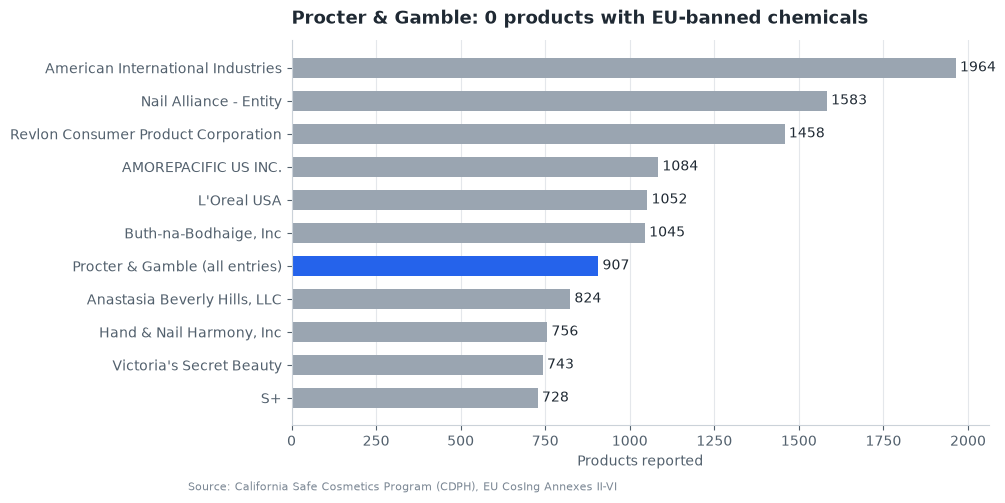

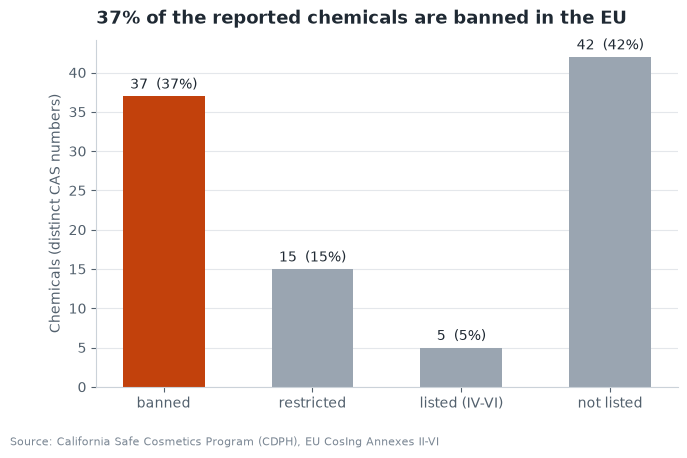

,chemical_name,cas_number
0,"1,4-Dioxane",123-91-1
1,"2,2-Bis(bromomethyl)-1,3-propanediol",3296-90-0
2,Acetaldehyde,75-07-0
3,Acrylamide,79-06-1
4,All-trans retinoic acid,302-79-4
5,Benz[a]anthracene,56-55-3
6,Benzene,71-43-2
7,Benzo[a]pyrene,50-32-8
8,Benzophenone,119-61-9
9,Benzyl chloride,100-44-7


In [5]:
import textwrap                                              # wraps long chemical names onto 2 lines
from matplotlib.patches import Patch                         # for a legend with coloured boxes

# --- Chart 6: top 10 chemicals WITHOUT titanium dioxide (EU-banned ones in the accent colour) ---
top = q("""SELECT ch.chemical_name, COUNT(DISTINCT r.cdph_id) AS products, MAX(r.eu_banned) AS banned
           FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
           WHERE ch.is_tio2 = 0
           GROUP BY ch.chemical_name ORDER BY products DESC LIMIT 10""")
labels = [textwrap.fill(n, 38) for n in top["chemical_name"]]                # wrap names longer than 38 characters
colors = [ACCENT if b else GREY for b in top["banned"]]                       # accent = banned in the EU
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels[::-1], top["products"][::-1], height=0.6, color=colors[::-1])   # [::-1] = largest on top
ax.bar_label(bars, padding=3, color=INK, fmt="%d")
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products containing the chemical", color="#52606D")
ax.legend(handles=[Patch(color=ACCENT, label="banned in the EU"), Patch(color=GREY, label="not banned")],
          frameon=False, loc="lower right")
style(ax, "Without titanium dioxide: silica and cocamide DEA are reported most often", SRC)
fig.savefig("../images/06_top_chemicals_no_tio2.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Chart 7: products per primary category (all reported products) ---
cats = q("""SELECT pc.primary_category, COUNT(DISTINCT pc.cdph_id) AS products
            FROM product_categories pc
            GROUP BY pc.primary_category ORDER BY products DESC LIMIT 10""")
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cats["primary_category"][::-1], cats["products"][::-1], height=0.6, color="#52606D")
ax.bar_label(bars, padding=3, color=INK, fmt="%d")
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products (a product can be in several categories)", color="#52606D")
style(ax, "Makeup, skin care and hair care dominate the reported products", SRC)
fig.savefig("../images/07_products_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Chart 8: top companies by number of products, Procter & Gamble marked ---
comp = q("""SELECT c.company_name, COUNT(DISTINCT r.cdph_id) AS products
            FROM reports r JOIN products p ON p.cdph_id = r.cdph_id
            JOIN companies c ON c.company_id = p.company_id
            GROUP BY c.company_name""")
is_pg = comp["company_name"].str.contains("Procter", case=False, na=False)    # all P&G spellings
print(comp[is_pg])                                                            # check which names were found
pg_row = pd.DataFrame({"company_name": ["Procter & Gamble (all entries)"], "products": [comp.loc[is_pg, "products"].sum()]})
show = pd.concat([comp[~is_pg].nlargest(10, "products"), pg_row]).sort_values("products", ascending=False)
pg_banned = q("""SELECT COUNT(DISTINCT r.cdph_id) AS n FROM reports r
                 JOIN products p ON p.cdph_id = r.cdph_id JOIN companies c ON c.company_id = p.company_id
                 WHERE c.company_name LIKE '%Procter%' AND r.eu_banned = 1""")["n"][0]
colors = ["#2563EB" if "Procter" in n else GREY for n in show["company_name"]]   # P&G in blue
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(show["company_name"][::-1], show["products"][::-1], height=0.6, color=colors[::-1])
ax.bar_label(bars, padding=3, color=INK, fmt="%d")
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_xlabel("Products reported", color="#52606D")
style(ax, f"Procter & Gamble: {pg_banned} products with EU-banned chemicals", SRC)
fig.savefig("../images/08_top_companies.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Chart 9: share of the reported CHEMICALS (distinct CAS) by EU status ---
share = q("""SELECT eu_status_of(cas_number) AS eu_status, COUNT(DISTINCT cas_number) AS chemicals
             FROM reports WHERE cas_number IS NOT NULL GROUP BY eu_status""")
order = ["banned", "restricted", "listed (IV-VI)", "not listed"]
share = share.set_index("eu_status").reindex(order).fillna(0).reset_index()
share["percent"] = 100 * share["chemicals"] / share["chemicals"].sum()
colors = [ACCENT if s == "banned" else GREY for s in share["eu_status"]]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(share["eu_status"], share["chemicals"], width=0.55, color=colors)
ax.bar_label(bars, labels=[f"{int(c)}  ({p:.0f}%)" for c, p in zip(share["chemicals"], share["percent"])],
             padding=3, color=INK)
ax.yaxis.grid(True, color="#E4E7EB")
ax.set_ylabel("Chemicals (distinct CAS numbers)", color="#52606D")
style(ax, f"{share.loc[0, 'percent']:.0f}% of the reported chemicals are banned in the EU", SRC)
fig.savefig("../images/09_share_by_eu_status.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Checkpoint: SQL lists the EU-banned chemicals ---
display(q("""SELECT DISTINCT ch.chemical_name, r.cas_number
             FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
             WHERE r.eu_banned = 1 ORDER BY ch.chemical_name"""))

**Chart 6: top 10 chemicals without TiO2**
   - **What it shows:** Without TiO2, crystalline silica (1,358 products) and cocamide diethanolamine (898) are reported most often; EU-banned chemicals are in the accent colour.
   - **Chemist's note:** Crystalline silica is hazardous mainly as respirable dust (quartz), not in every bound form. Cocamide DEA is a foam booster that can contain diethanolamine as an impurity.
     
**Chart 7: products by category**

- **What it shows:** [Makeup, nail product and skin care] contain most of the reported products.
- **Note:** A product can belong to several categories, so the bars add up to more than the number of products.

**Chart 8: top companies, P&G marked**

- **What it shows:** Procter & Gamble has [907] reported products and [0] with an EU-banned chemical in this dataset.
- **Note:** Counts reflect the size of a company's product range, not product quality. The statement is limited to this dataset: "no EU-banned chemical reported", not "safer than others".

**Chart 9: share by EU status**

- **What it shows:** [37] of the [107] reported chemicals with a CAS number ([35]%) are banned in the EU, and [20] more are restricted.
- **Chemist's note:** Impurities such as 1,4-dioxane count as banned here, although the EU tolerates traces. Group entries without one CAS number (for example mineral oils or retinol esters) cannot be matched, so the true share may be higher.


## Summary: EDA, chapters 1 and 2

| Topic | Result |
|---|---|
| Data | 114,381 reports, 36,972 products, 635 companies, 134 chemicals (2009-June 2020) |
| Most frequent chemical | Titanium dioxide in 32,010 products (about 87%); without TiO2: [silica, cocamide DEA] |
| Reporting over time | Initial wave 2009-2010; 1,400-4,600 new products per year after; 2020 incomplete |
| EU status of reported chemicals | [37] of 107 chemicals with CAS are banned (Annex II), 20 restricted (Annex III) |
| Affected | 845 reports, 455 products and 86 companies contain an EU-banned chemical |
| Removal rate (without TiO2) | banned 16.7% vs not listed 7.2%, listed 4.5%, restricted 3.0% |
| Most affected categories | Skin care, hair care, makeup, nail products |
| Procter & Gamble | [907] products, [0] with an EU-banned chemical in this dataset |

**Interpretation:** The EU rulebook and the California reports overlap strongly, and EU-banned chemicals were removed most often. Many banned hits are impurities or particle forms, so presence does not equal risk.

**Limits:** No amounts in the data; group entries without CAS cannot be matched; 2009-2010 reflects the start of the program; association, not causation.

**Next:** H1 chi-square test (is the removal difference more than chance?), then Sephora.